In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession
from pyspark.sql.functions import *

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
spark = SparkSession.builder \
    .appName("CartToDoor_Delivery_Analysis") \
    .master("local[*]") \
    .config("spark.sql.shuffle.partitions", "4") \
    .getOrCreate()

print("Spark Session Started Successfully!")
print("Spark Version:", spark.version)

Spark Session Started Successfully!
Spark Version: 3.5.3


In [3]:
dataset_path = os.path.join(os.getcwd(), "01_Dataset")

print("Current Folder:", os.getcwd())
print("Dataset Folder Exists:", os.path.exists(dataset_path))
print("Dataset Files:", os.listdir(dataset_path))

Current Folder: C:\Users\dell\Desktop\CART_TO_DOOR_PROJECT
Dataset Folder Exists: True
Dataset Files: ['olist_customers_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_orders_dataset.csv', 'olist_order_items_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_products_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv']


In [4]:
orders = spark.read.csv(
    os.path.join(dataset_path, "olist_orders_dataset.csv"),
    header=True,
    inferSchema=True
)

customers = spark.read.csv(
    os.path.join(dataset_path, "olist_customers_dataset.csv"),
    header=True,
    inferSchema=True
)

print("Orders loaded:", orders.count())
print("Customers loaded:", customers.count())

Orders loaded: 99441
Customers loaded: 99441


In [5]:
reviews = spark.read \
    .option("header", "true") \
    .option("inferSchema", "true") \
    .option("multiLine", "true") \
    .option("quote", '"') \
    .option("escape", '"') \
    .csv(os.path.join(dataset_path, "olist_order_reviews_dataset.csv"))

print("Total Reviews:", reviews.count())

Total Reviews: 99224


In [6]:
print("Reviews Schema:")
reviews.printSchema()

print("First 5 Reviews:")
reviews.show(5, truncate=False)

Reviews Schema:
root
 |-- review_id: string (nullable = true)
 |-- order_id: string (nullable = true)
 |-- review_score: integer (nullable = true)
 |-- review_comment_title: string (nullable = true)
 |-- review_comment_message: string (nullable = true)
 |-- review_creation_date: timestamp (nullable = true)
 |-- review_answer_timestamp: timestamp (nullable = true)

First 5 Reviews:
+--------------------------------+--------------------------------+------------+--------------------+----------------------------------------------------------------------------------------------------+--------------------+-----------------------+
|review_id                       |order_id                        |review_score|review_comment_title|review_comment_message                                                                              |review_creation_date|review_answer_timestamp|
+--------------------------------+--------------------------------+------------+--------------------+-------------------

In [7]:
print("Review Score Distribution:")

reviews.groupBy("review_score") \
    .count() \
    .orderBy("review_score") \
    .show()

print("Average Review Score:")

reviews.select(
    avg("review_score").alias("Average_Rating")
).show()

Review Score Distribution:
+------------+-----+
|review_score|count|
+------------+-----+
|           1|11424|
|           2| 3151|
|           3| 8179|
|           4|19142|
|           5|57328|
+------------+-----+

Average Review Score:
+----------------+
|  Average_Rating|
+----------------+
|4.08642062404257|
+----------------+



In [8]:
reviews = reviews.withColumn(
    "review_category",
    when(col("review_score") <= 2, "Negative")
    .when(col("review_score") == 3, "Neutral")
    .otherwise("Positive")
)

print("Review Category Distribution:")

reviews.groupBy("review_category") \
    .count() \
    .orderBy("review_category") \
    .show()

Review Category Distribution:
+---------------+-----+
|review_category|count|
+---------------+-----+
|       Negative|14575|
|        Neutral| 8179|
|       Positive|76470|
+---------------+-----+



In [9]:
negative_reviews = reviews.filter(
    (col("review_score") <= 2) &
    (col("review_comment_message").isNotNull())
)

print("Total Negative Reviews with Comments:", negative_reviews.count())

negative_reviews.select(
    "order_id",
    "review_score",
    "review_comment_title",
    "review_comment_message"
).show(20, truncate=50)

Total Negative Reviews with Comments: 10890
+--------------------------------+------------+-------------------------+--------------------------------------------------+
|                        order_id|review_score|     review_comment_title|                            review_comment_message|
+--------------------------------+------------+-------------------------+--------------------------------------------------+
|0dacf04c5ad59fd5a0cc1faa07c34e39|           2|                     NULL|GOSTARIA DE SABER O QUE HOUVE, SEMPRE RECEBI E ...|
|583174fbe37d3d5f0d6661be3aad1786|           1|  Não chegou meu produto |                                           Péssimo|
|0ce9a24111d850192a933fcaab6fbad3|           1|                     NULL|               Não gostei ! Comprei gato por lebre|
|68e55ca79d04a79f20d4bfc0146f4b66|           1|                     NULL|Sempre compro pela Internet e a entrega ocorre ...|
|3c314f50bc654f3c4e317b055681dff9|           1|                     NULL|        

In [10]:
total_reviews = reviews.count()

category_summary = reviews.groupBy("review_category") \
    .count() \
    .withColumn(
        "percentage",
        round((col("count") / total_reviews) * 100, 2)
    ) \
    .orderBy("review_category")

category_summary.show()

+---------------+-----+----------+
|review_category|count|percentage|
+---------------+-----+----------+
|       Negative|14575|     14.69|
|        Neutral| 8179|      8.24|
|       Positive|76470|     77.07|
+---------------+-----+----------+



In [11]:
delivery = orders.select(
    "order_id",
    "customer_id",
    "order_status",
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
)

print("Delivery columns selected successfully!")
delivery.show(5, truncate=False)

Delivery columns selected successfully!
+--------------------------------+--------------------------------+------------+------------------------+-----------------------------+-----------------------------+
|order_id                        |customer_id                     |order_status|order_purchase_timestamp|order_delivered_customer_date|order_estimated_delivery_date|
+--------------------------------+--------------------------------+------------+------------------------+-----------------------------+-----------------------------+
|e481f51cbdc54678b7cc49136f2d6af7|9ef432eb6251297304e76186b10a928d|delivered   |2017-10-02 10:56:33     |2017-10-10 21:25:13          |2017-10-18 00:00:00          |
|53cdb2fc8bc7dce0b6741e2150273451|b0830fb4747a6c6d20dea0b8c802d7ef|delivered   |2018-07-24 20:41:37     |2018-08-07 15:27:45          |2018-08-13 00:00:00          |
|47770eb9100c2d0c44946d9cf07ec65d|41ce2a54c0b03bf3443c3d931a367089|delivered   |2018-08-08 08:38:49     |2018-08-17 18:06:29      

In [28]:
delivery = delivery.withColumn(
    "delivery_days",
    datediff(
        to_date("actual_delivery"),
        to_date("order_purchase_timestamp")
    )
)

print("Delivery days calculated successfully!")

delivery.select(
    "order_id",
    "delivery_days"
).show(10)

Delivery days calculated successfully!
+--------------------+-------------+
|            order_id|delivery_days|
+--------------------+-------------+
|e481f51cbdc54678b...|            8|
|53cdb2fc8bc7dce0b...|           14|
|47770eb9100c2d0c4...|            9|
|949d5b44dbf5de918...|           14|
|ad21c59c0840e6cb8...|            3|
|a4591c265e18cb1dc...|           17|
|136cce7faa42fdb2c...|         NULL|
|6514b8ad8028c9f2c...|           10|
|76c6e866289321a7c...|           10|
|e69bfb5eb88e0ed6a...|           18|
+--------------------+-------------+
only showing top 10 rows



In [29]:
delivery = delivery.withColumn(
    "actual_delivery",
    to_timestamp("order_delivered_customer_date")
).withColumn(
    "estimated_delivery",
    to_timestamp("order_estimated_delivery_date")
).withColumn(
    "purchase_date",
    to_timestamp("order_purchase_timestamp")
)

print("All delivery dates converted successfully!")
delivery.show(5, truncate=False)

All delivery dates converted successfully!
+--------------------------------+--------------------------------+------------+------------------------+-----------------------------+-----------------------------+-------------------+-------------------+-------------------+-------------+
|order_id                        |customer_id                     |order_status|order_purchase_timestamp|order_delivered_customer_date|order_estimated_delivery_date|actual_delivery    |estimated_delivery |purchase_date      |delivery_days|
+--------------------------------+--------------------------------+------------+------------------------+-----------------------------+-----------------------------+-------------------+-------------------+-------------------+-------------+
|e481f51cbdc54678b7cc49136f2d6af7|9ef432eb6251297304e76186b10a928d|delivered   |2017-10-02 10:56:33     |2017-10-10 21:25:13          |2017-10-18 00:00:00          |2017-10-10 21:25:13|2017-10-18 00:00:00|2017-10-02 10:56:33|8           

In [30]:
delivery = delivery.withColumn(
    "delivery_days",
    datediff(
        to_date("actual_delivery"),
        to_date("purchase_date")
    )
)

print("Delivery days calculated successfully!")

delivery.select(
    "order_id",
    "purchase_date",
    "actual_delivery",
    "delivery_days"
).show(10, truncate=False)

Delivery days calculated successfully!
+--------------------------------+-------------------+-------------------+-------------+
|order_id                        |purchase_date      |actual_delivery    |delivery_days|
+--------------------------------+-------------------+-------------------+-------------+
|e481f51cbdc54678b7cc49136f2d6af7|2017-10-02 10:56:33|2017-10-10 21:25:13|8            |
|53cdb2fc8bc7dce0b6741e2150273451|2018-07-24 20:41:37|2018-08-07 15:27:45|14           |
|47770eb9100c2d0c44946d9cf07ec65d|2018-08-08 08:38:49|2018-08-17 18:06:29|9            |
|949d5b44dbf5de918fe9c16f97b45f8a|2017-11-18 19:28:06|2017-12-02 00:28:42|14           |
|ad21c59c0840e6cb83a9ceb5573f8159|2018-02-13 21:18:39|2018-02-16 18:17:02|3            |
|a4591c265e18cb1dcee52889e2d8acc3|2017-07-09 21:57:05|2017-07-26 10:57:55|17           |
|136cce7faa42fdb2cefd53fdc79a6098|2017-04-11 12:22:08|NULL               |NULL         |
|6514b8ad8028c9f2cc2374ded245783f|2017-05-16 13:10:30|2017-05-26 12:55:

In [31]:
delivered_orders = delivery.filter(
    (col("order_status") == "delivered") &
    col("actual_delivery").isNotNull() &
    col("estimated_delivery").isNotNull() &
    (to_date("actual_delivery") >= to_date("purchase_date")) &
    (col("delivery_days") >= 0)
)

print("Total Valid Delivered Orders:", delivered_orders.count())

delivered_orders.select(
    "order_id",
    "delivery_days",
    "actual_delivery",
    "estimated_delivery"
).show(10, truncate=False)

Total Valid Delivered Orders: 96470
+--------------------------------+-------------+-------------------+-------------------+
|order_id                        |delivery_days|actual_delivery    |estimated_delivery |
+--------------------------------+-------------+-------------------+-------------------+
|e481f51cbdc54678b7cc49136f2d6af7|8            |2017-10-10 21:25:13|2017-10-18 00:00:00|
|53cdb2fc8bc7dce0b6741e2150273451|14           |2018-08-07 15:27:45|2018-08-13 00:00:00|
|47770eb9100c2d0c44946d9cf07ec65d|9            |2018-08-17 18:06:29|2018-09-04 00:00:00|
|949d5b44dbf5de918fe9c16f97b45f8a|14           |2017-12-02 00:28:42|2017-12-15 00:00:00|
|ad21c59c0840e6cb83a9ceb5573f8159|3            |2018-02-16 18:17:02|2018-02-26 00:00:00|
|a4591c265e18cb1dcee52889e2d8acc3|17           |2017-07-26 10:57:55|2017-08-01 00:00:00|
|6514b8ad8028c9f2cc2374ded245783f|10           |2017-05-26 12:55:51|2017-06-07 00:00:00|
|76c6e866289321a7c93b82b54852dc33|10           |2017-02-02 14:08:10|2017-0

In [32]:
print("Delivery Time Statistics:")

delivered_orders.select(
    avg("delivery_days").alias("Average_Delivery_Days"),
    min("delivery_days").alias("Minimum_Delivery_Days"),
    max("delivery_days").alias("Maximum_Delivery_Days")
).show()

median_days = delivered_orders.approxQuantile(
    "delivery_days", [0.5], 0.01
)[0]

print("Median Delivery Days:", median_days)

Delivery Time Statistics:
+---------------------+---------------------+---------------------+
|Average_Delivery_Days|Minimum_Delivery_Days|Maximum_Delivery_Days|
+---------------------+---------------------+---------------------+
|   12.496848761272934|                    0|                  210|
+---------------------+---------------------+---------------------+

Median Delivery Days: 10.0


In [33]:
delivered_orders = delivered_orders.withColumn(
    "delivery_status",
    when(
        to_date("actual_delivery") <= to_date("estimated_delivery"),
        "On Time"
    ).otherwise("Late")
)

print("Delivery Status Distribution:")

delivered_orders.groupBy("delivery_status") \
    .count() \
    .orderBy("delivery_status") \
    .show()

Delivery Status Distribution:
+---------------+-----+
|delivery_status|count|
+---------------+-----+
|           Late| 6534|
|        On Time|89936|
+---------------+-----+



In [34]:
total_orders = delivered_orders.count()

status_summary = delivered_orders.groupBy("delivery_status") \
    .count() \
    .withColumn(
        "percentage",
        round((col("count") / total_orders) * 100, 2)
    )

status_summary.orderBy("delivery_status").show()

+---------------+-----+----------+
|delivery_status|count|percentage|
+---------------+-----+----------+
|           Late| 6534|      6.77|
|        On Time|89936|     93.23|
+---------------+-----+----------+



In [35]:
state_delivery = delivered_orders.join(
    customers.select("customer_id", "customer_state"),
    on="customer_id",
    how="inner"
)

print("Delivery data joined with customer states!")
print("Joined Orders:", state_delivery.count())

state_delivery.select(
    "order_id",
    "customer_id",
    "customer_state",
    "delivery_days",
    "delivery_status"
).show(10, truncate=False)

Delivery data joined with customer states!
Joined Orders: 96470
+--------------------------------+--------------------------------+--------------+-------------+---------------+
|order_id                        |customer_id                     |customer_state|delivery_days|delivery_status|
+--------------------------------+--------------------------------+--------------+-------------+---------------+
|e481f51cbdc54678b7cc49136f2d6af7|9ef432eb6251297304e76186b10a928d|SP            |8            |On Time        |
|53cdb2fc8bc7dce0b6741e2150273451|b0830fb4747a6c6d20dea0b8c802d7ef|BA            |14           |On Time        |
|47770eb9100c2d0c44946d9cf07ec65d|41ce2a54c0b03bf3443c3d931a367089|GO            |9            |On Time        |
|949d5b44dbf5de918fe9c16f97b45f8a|f88197465ea7920adcdbec7375364d82|RN            |14           |On Time        |
|ad21c59c0840e6cb83a9ceb5573f8159|8ab97904e6daea8866dbdbc4fb7aad2c|SP            |3            |On Time        |
|a4591c265e18cb1dcee52889e2d8acc

In [36]:
state_avg_delivery = state_delivery.groupBy("customer_state") \
    .agg(
        avg("delivery_days").alias("Average_Delivery_Days"),
        count("order_id").alias("Total_Orders")
    ) \
    .orderBy("Average_Delivery_Days")

print("Fastest Delivery States:")
state_avg_delivery.show(10, truncate=False)

print("Slowest Delivery States:")
state_avg_delivery.orderBy(
    col("Average_Delivery_Days").desc()
).show(10, truncate=False)

Fastest Delivery States:
+--------------+---------------------+------------+
|customer_state|Average_Delivery_Days|Total_Orders|
+--------------+---------------------+------------+
|SP            |8.70057292438386     |40494       |
|PR            |11.938045906967297   |4923        |
|MG            |11.944953320415712   |11354       |
|DF            |12.899038461538462   |2080        |
|SC            |14.902989283699943   |3546        |
|RJ            |15.237004048582996   |12350       |
|RS            |15.248502994011975   |5344        |
|GO            |15.536024527337762   |1957        |
|MS            |15.544935805991441   |701         |
|ES            |15.723809523809523   |1995        |
+--------------+---------------------+------------+
only showing top 10 rows

Slowest Delivery States:
+--------------+---------------------+------------+
|customer_state|Average_Delivery_Days|Total_Orders|
+--------------+---------------------+------------+
|RR            |29.341463414634145   |41

In [37]:
state_late_delivery = state_delivery.groupBy("customer_state") \
    .agg(
        count("order_id").alias("Total_Orders"),
        sum(when(col("delivery_status") == "Late", 1).otherwise(0)).alias("Late_Orders")
    ) \
    .withColumn(
        "Late_Percentage",
        round((col("Late_Orders") / col("Total_Orders")) * 100, 2)
    ) \
    .orderBy(col("Late_Percentage").desc())

print("Top 10 States with Highest Late Delivery Percentage:")
state_late_delivery.show(10, truncate=False)

Top 10 States with Highest Late Delivery Percentage:
+--------------+------------+-----------+---------------+
|customer_state|Total_Orders|Late_Orders|Late_Percentage|
+--------------+------------+-----------+---------------+
|AL            |397         |85         |21.41          |
|MA            |717         |125        |17.43          |
|SE            |335         |51         |15.22          |
|PI            |476         |66         |13.87          |
|CE            |1279        |176        |13.76          |
|RR            |41          |5          |12.2           |
|BA            |3256        |396        |12.16          |
|RJ            |12350       |1495       |12.11          |
|PA            |946         |106        |11.21          |
|ES            |1995        |214        |10.73          |
+--------------+------------+-----------+---------------+
only showing top 10 rows



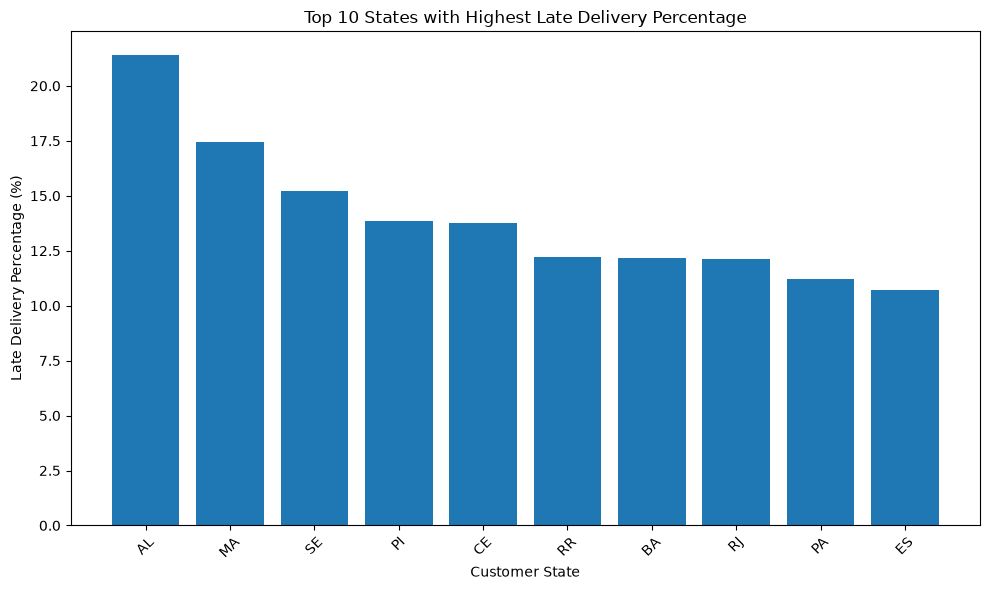

In [38]:
import matplotlib.pyplot as plt

state_late_pd = state_late_delivery.limit(10).toPandas()

plt.figure(figsize=(10, 6))

plt.bar(
    state_late_pd["customer_state"],
    state_late_pd["Late_Percentage"]
)

plt.title("Top 10 States with Highest Late Delivery Percentage")
plt.xlabel("Customer State")
plt.ylabel("Late Delivery Percentage (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

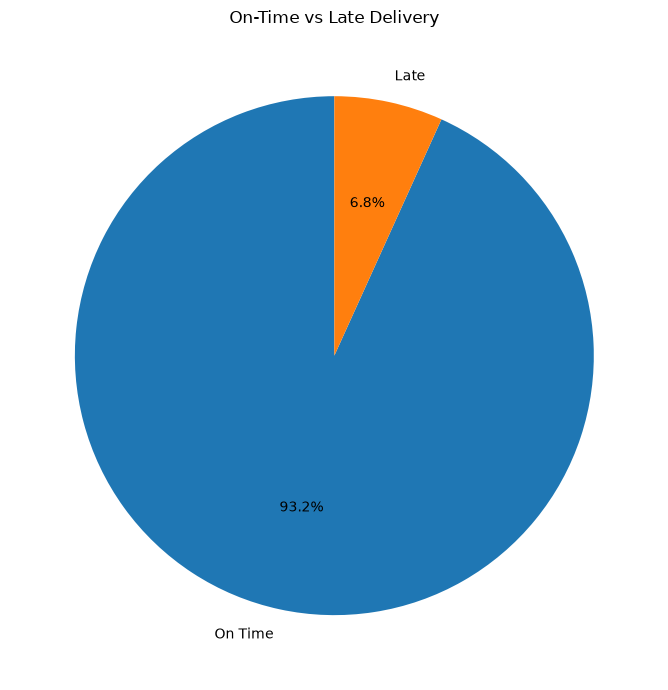

In [39]:
delivery_status_pd = delivered_orders.groupBy("delivery_status") \
    .count() \
    .toPandas()

plt.figure(figsize=(7, 7))

plt.pie(
    delivery_status_pd["count"],
    labels=delivery_status_pd["delivery_status"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("On-Time vs Late Delivery")
plt.tight_layout()
plt.show()

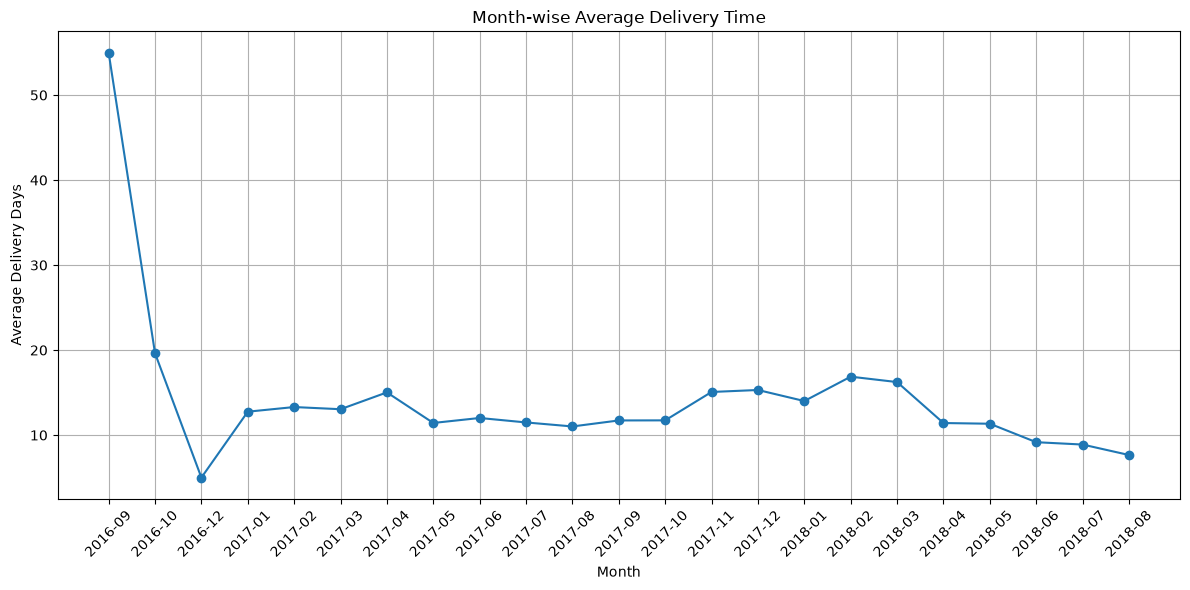

In [40]:
monthly_delivery = delivered_orders.withColumn(
    "Month",
    date_format("purchase_date", "yyyy-MM")
).groupBy("Month").agg(
    avg("delivery_days").alias("Average_Delivery_Days")
).orderBy("Month")

monthly_pd = monthly_delivery.toPandas()

plt.figure(figsize=(12, 6))
plt.plot(
    monthly_pd["Month"],
    monthly_pd["Average_Delivery_Days"],
    marker="o"
)

plt.title("Month-wise Average Delivery Time")
plt.xlabel("Month")
plt.ylabel("Average Delivery Days")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [41]:
from pyspark.sql.functions import datediff, to_date

delivery_summary = state_delivery.withColumn(
    "delay_days",
    datediff(
        to_date("actual_delivery"),
        to_date("estimated_delivery")
    )
).select(
    "order_id",
    "customer_id",
    "customer_state",
    "purchase_date",
    "actual_delivery",
    "estimated_delivery",
    "delivery_days",
    "delay_days",
    "delivery_status"
)

output_path = os.path.join(
    os.getcwd(),
    "04_Delivery_Reviews",
    "delivery_summary.csv"
)

delivery_summary.toPandas().to_csv(output_path, index=False)

print("Delivery summary CSV saved successfully!")
print("Total rows:", delivery_summary.count())
print("Saved at:", output_path)

Delivery summary CSV saved successfully!
Total rows: 96470
Saved at: C:\Users\dell\Desktop\CART_TO_DOOR_PROJECT\04_Delivery_Reviews\delivery_summary.csv
